# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** [I Putu Mahadi Putra Ananta]
- **Email:** [ds014b6y0763@student.devacademy.id]
- **ID Dicoding:** [mahadiputra]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total pendapatan (*revenue*) tertinggi dan terendah berdasarkan transaksi pesanan di platform sepanjang tahun 2018?
- **Pertanyaan 2:** Di negara bagian (*state*) manakah jumlah pelanggan terbanyak berada berdasarkan data transaksi selama tahun 2018, dan bagaimana persebaran jumlah pelanggan di setiap negara bagian?

### Evaluasi Prinsip SMART:
1. **Specific (Spesifik):** Pertanyaan 1 berfokus pada kategori produk dengan total *revenue* tertinggi dan terendah, sedangkan Pertanyaan 2 berfokus pada identifikasi negara bagian dengan pelanggan terbanyak serta persebaran pelanggan di setiap negara bagian.
2. **Measurable (Terukur):** Diukur secara kuantitatif melalui total nilai pendapatan produk (dalam satuan BRL / R$), jumlah pelanggan unik (`customer_unique_id`), serta persentase kontribusi masing-masing kategori dan negara bagian.
3. **Action-oriented (Dapat Ditindaklanjuti):** Hasil analisis dapat digunakan untuk menentukan prioritas alokasi anggaran promosi produk, pengelolaan stok inventaris, serta strategi ekspansi logistik dan pergudangan pada wilayah dengan konsentrasi pelanggan tinggi.
4. **Relevant (Relevan):** Performa pendapatan kategori produk dan distribusi geografis pelanggan merupakan metrik inti dalam mengevaluasi pertumbuhan bisnis *e-commerce*.
5. **Time-bound (Terikat Waktu):** Kedua pertanyaan memiliki batasan periode waktu yang jelas dan seragam, yakni sepanjang **tahun 2018**.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi global
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

## Data Wrangling

### Gathering Data

#### Load Dataset E-Commerce

In [2]:
# Menentukan path folder dataset secara dinamis agar aman dijalankan dari folder mana pun
data_dir = "data" if os.path.exists("data") else "."

orders_df = pd.read_csv(os.path.join(data_dir, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(data_dir, "order_items_dataset.csv"))
products_df = pd.read_csv(os.path.join(data_dir, "products_dataset.csv"))
category_trans_df = pd.read_csv(os.path.join(data_dir, "product_category_name_translation.csv"))
customers_df = pd.read_csv(os.path.join(data_dir, "customers_dataset.csv"))

print("Seluruh 5 dataset utama berhasil dimuat!")

Seluruh 5 dataset utama berhasil dimuat!


**Insight:** (Opsional)

- Sebanyak 5 tabel utama (`orders_df`, `order_items_df`, `products_df`, `category_trans_df`, dan `customers_df`) berhasil dimuat ke dalam DataFrame.
- Tabel lain seperti `geolocation_dataset.csv` tidak dimuat karena analisis geografis pada Pertanyaan 2 berfokus pada tingkat negara bagian (`customer_state`) yang sudah tersedia di `customers_df`, sehingga penggunaan memori menjadi lebih efisien.

### Assessing Data

#### Identifying Data Quality Problems

In [3]:
datasets = {
    "orders_df": orders_df,
    "order_items_df": order_items_df,
    "products_df": products_df,
    "category_trans_df": category_trans_df,
    "customers_df": customers_df
}

for name, df in datasets.items():
    print("=" * 60)
    print(f"PEMERIKSAAN DATASET: {name} (Baris: {df.shape[0]}, Kolom: {df.shape[1]})")
    print("=" * 60)

    print("\n1. Informasi Struktur & Tipe Data:")
    df.info()

    print("\n2. Jumlah Missing Values per Kolom:")
    missing = df.isna().sum()
    print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing values.")

    print(f"\n3. Jumlah Data Duplikat: {df.duplicated().sum()}")

    print("\n4. Ringkasan Statistik Numerik:")
    num_cols = df.select_dtypes(include=[np.number])
    if not num_cols.empty:
        print(num_cols.describe().round(2))
    else:
        print("Tidak ada kolom numerik.")
    print("\n")

PEMERIKSAAN DATASET: orders_df (Baris: 99441, Kolom: 8)

1. Informasi Struktur & Tipe Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

2. Jumlah Missing Values per Kolom:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

3. Ju

**Steps to Take:**
- Konversi Tipe Data Waktu:** Mengubah tipe data kolom tanggal yang masih berupa `object` menjadi `datetime64[ns]`, meliputi 5 kolom waktu pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date`) serta kolom `shipping_limit_date` pada `order_items_df`.

- Penanganan Missing Values pada `products_df`:** Mengisi 610 nilai kosong pada kolom `product_category_name` dengan label `'unknown'` agar transaksi produk tanpa kategori tetap terhitung dalam total pendapatan, menambahkan baris padanan `'unknown'` pada `category_trans_df` agar tidak menghasilkan `NaN` saat proses *merge*, serta mengisi *missing values* pada kolom numerik atribut/dimensi produk menggunakan nilai median.

- Mempertahankan Missing Values Status Pesanan pada `orders_df`:** Tidak menghapus baris kosong pada kolom `order_approved_at`, `order_delivered_carrier_date`, dan `order_delivered_customer_date` karena kondisi tersebut mencerminkan status pesanan yang wajar (misalnya pesanan dibatalkan atau belum terkirim).

**Insight:** (Opsional)

- `orders_df` (99.441 baris, 8 kolom): Tidak terdapat data duplikat (`0`), namun ditemukan kesalahan tipe data pada 5 kolom waktu yang masih bertipe `object` serta *missing values* pada `order_approved_at` (160 baris), `order_delivered_carrier_date` (1.783 baris), dan `order_delivered_customer_date` (2.965 baris).

- `order_items_df` (112.650 baris, 7 kolom): Bersih dari *missing values* dan data duplikat (`0`), dengan rentang statistik `price` dan `freight_value` yang wajar, namun kolom `shipping_limit_date` masih bertipe `object`.

- `products_df` (32.951 baris, 9 kolom): Tidak terdapat data duplikat (`0`), tetapi ditemukan *missing values* sebanyak 610 baris pada kolom `product_category_name`, `product_name_lenght`, `product_description_lenght`, dan `product_photos_qty`, serta 2 baris kosong pada kolom dimensi berat dan ukuran produk (`product_weight_g`, `product_length_cm`, `product_height_cm`, `product_width_cm`).

- `category_trans_df` (71 baris, 2 kolom): Bersih tanpa *missing values* maupun data duplikat (`0`).

- `customers_df` (99.441 baris, 5 kolom): Bersih tanpa *missing values* maupun data duplikat (`0`), dengan perbedaan identitas antara `customer_id` (unik per transaksi) dan `customer_unique_id` (unik per individu pelanggan).

### Cleaning Data

#### Fixing Data Quality Problems

In [4]:
# 1. Konversi kolom tanggal pada orders_df menjadi datetime
order_datetime_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in order_datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Konversi kolom tanggal pada order_items_df menjadi datetime
order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])

# 3. Menangani missing values pada products_df
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")

numeric_product_cols = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]
for col in numeric_product_cols:
    products_df[col] = products_df[col].fillna(products_df[col].median())

# 4. Menambahkan kategori 'unknown' pada tabel terjemahan kategori agar konsisten saat merge
unknown_cat = pd.DataFrame({
    "product_category_name": ["unknown"],
    "product_category_name_english": ["unknown"]
})
category_trans_df = pd.concat([category_trans_df, unknown_cat], ignore_index=True).drop_duplicates()

# Verifikasi hasil pembersihan
print("Tipe data orders_df setelah cleaning:")
print(orders_df[order_datetime_cols].dtypes)
print("\nJumlah missing values products_df setelah cleaning:", products_df.isna().sum().sum())

Tipe data orders_df setelah cleaning:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Jumlah missing values products_df setelah cleaning: 0


**Insight:** (Opsional)
- Standarisasi Format Waktu: Seluruh kolom tanggal pada `orders_df` dan kolom `shipping_limit_date` pada `order_items_df` telah berhasil dikonversi dari tipe `object` menjadi `datetime64[ns]`, sehingga pemfilteran transaksi untuk periode tahun 2018 dapat dilakukan secara akurat.

- Penanganan Data Kosong Tanpa Menghilangkan Transaksi: Sebanyak 610 baris produk yang tidak memiliki nama kategori pada `products_df` telah diisi dengan label `'unknown'` (beserta padanannya di `category_trans_df`), sedangkan *missing values* pada kolom dimensi produk diisi menggunakan nilai median sehingga total *missing values* pada `products_df` menjadi `0` tanpa mengurangi volume data transaksi.

- Kesiapan Dataset untuk Tahap Eksplorasi: Kelima tabel utama kini telah memiliki tipe data yang sesuai, bebas dari duplikasi, dan siap digabungkan untuk menjawab kedua pertanyaan bisnis pada tahap *Exploratory Data Analysis (EDA)*.

## Exploratory Data Analysis (EDA)

### Explore Pendapatan Kategori & Persebaran Pelanggan Tahun 2018

In [5]:
# 1. Menggabungkan seluruh tabel transaksi yang bersih untuk analisis terpadu
all_df = pd.merge(
    orders_df[["order_id", "customer_id", "order_status", "order_purchase_timestamp"]],
    order_items_df[["order_id", "order_item_id", "product_id", "price", "freight_value"]],
    on="order_id",
    how="inner"
)
all_df = pd.merge(all_df, products_df[["product_id", "product_category_name"]], on="product_id", how="left")
all_df = pd.merge(all_df, category_trans_df, on="product_category_name", how="left")
all_df["product_category_name_english"] = all_df["product_category_name_english"].fillna("unknown")
all_df = pd.merge(
    all_df,
    customers_df[["customer_id", "customer_unique_id", "customer_city", "customer_state"]],
    on="customer_id",
    how="left"
)

# Menambahkan kolom tahun transaksi
all_df["order_year"] = all_df["order_purchase_timestamp"].dt.year

# Filter khusus transaksi sepanjang tahun 2018
df_2018 = all_df[all_df["order_year"] == 2018].copy()

print(f"Total item transaksi tahun 2018 : {len(df_2018):,} item")
print(f"Total pesanan unik tahun 2018   : {df_2018['order_id'].nunique():,} pesanan")
print(f"Total pendapatan tahun 2018     : R$ {df_2018['price'].sum():,.2f}")
print(f"Total pelanggan unik tahun 2018 : {df_2018['customer_unique_id'].nunique():,} pelanggan")

# 2. EDA Pertanyaan 1: Total Pendapatan (Revenue) per Kategori Produk (2018)
revenue_by_category_2018 = (
    df_2018.groupby("product_category_name_english", as_index=False)
    .agg(
        total_revenue=("price", "sum"),
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count")
    )
    .sort_values(by="total_revenue", ascending=False)
    .reset_index(drop=True)
)

total_rev_2018 = revenue_by_category_2018["total_revenue"].sum()
revenue_by_category_2018["revenue_share (%)"] = (
    revenue_by_category_2018["total_revenue"] / total_rev_2018 * 100
).round(2)

print("\n--- TOP 5 KATEGORI PENDAPATAN TERTINGGI (2018) ---")
print(revenue_by_category_2018.head(5))

print("\n--- BOTTOM 5 KATEGORI PENDAPATAN TERENDAH (2018) ---")
print(revenue_by_category_2018.tail(5))

# 3. EDA Pertanyaan 2: Persebaran Pelanggan per Negara Bagian / State (2018)
customer_by_state_2018 = (
    df_2018.groupby("customer_state", as_index=False)
    .agg(
        unique_customers=("customer_unique_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_revenue=("price", "sum")
    )
    .sort_values(by="unique_customers", ascending=False)
    .reset_index(drop=True)
)

total_cust_2018 = customer_by_state_2018["unique_customers"].sum()
customer_by_state_2018["customer_share (%)"] = (
    customer_by_state_2018["unique_customers"] / total_cust_2018 * 100
).round(2)

print(f"\nJumlah Negara Bagian Aktif Bertransaksi (2018): {len(customer_by_state_2018)} negara bagian")
print("\n--- PERSEBARAN PELANGGAN DI SELURUH NEGARA BAGIAN (2018) ---")
print(customer_by_state_2018)

Total item transaksi tahun 2018 : 61,416 item
Total pesanan unik tahun 2018   : 53,775 pesanan
Total pendapatan tahun 2018     : R$ 7,386,050.80
Total pelanggan unik tahun 2018 : 52,565 pelanggan

--- TOP 5 KATEGORI PENDAPATAN TERTINGGI (2018) ---
  product_category_name_english  total_revenue  total_orders  total_items  \
0                 health_beauty      772238.15          5402         5951   
1                 watches_gifts      708850.94          3493         3703   
2                bed_bath_table      538069.26          4909         5884   
3                sports_leisure      532566.49          4058         4527   
4         computers_accessories      505476.31          4053         4708   

   revenue_share (%)  
0              10.46  
1               9.60  
2               7.28  
3               7.21  
4               6.84  

--- BOTTOM 5 KATEGORI PENDAPATAN TERENDAH (2018) ---
   product_category_name_english  total_revenue  total_orders  total_items  \
66        fashio_fe

**Insight:** (Opsional)
* **Performa Pendapatan Kategori Produk (Tahun 2018):** Kategori **`health_beauty`** menempati peringkat pertama sebagai penyumbang pendapatan (*revenue*) tertinggi sepanjang tahun 2018, diikuti oleh **`watches_gifts`**, **`bed_bath_table`**, **`sports_leisure`**, dan **`computers_accessories`**. Sebaliknya, kategori seperti **`security_and_services`**, **`fashion_childrens_clothes`**, dan **`cds_dvds_musicals`** berada di posisi terbawah dengan kontribusi pendapatan yang sangat kecil terhadap total penjualan platform.

* **Negara Bagian dengan Pelanggan Terbanyak (Tahun 2018):** Negara bagian **SP (São Paulo)** mendominasi basis pelanggan unik pada tahun 2018 dengan jumlah **23.184 pelanggan** atau menyumbang **44,10%** dari total keseluruhan pelanggan, diikuti oleh **RJ (Rio de Janeiro)** sebanyak **6.380 pelanggan (12,14%)** dan **MG (Minas Gerais)** sebanyak **6.026 pelanggan (11,46%)**.

* **Ketimpangan Persebaran Geografis:** Seluruh **27 negara bagian** di Brasil tercatat melakukan transaksi pada tahun 2018, namun persebarannya sangat terpusat di wilayah tenggara (*Southeast*), di mana tiga negara bagian teratas (**SP, RJ, dan MG**) secara kolektif mencakup **35.590 pelanggan (67,70%)**. Sementara itu, negara bagian di wilayah utara seperti **RR (Roraima)** (25 pelanggan / 0,05%), **AC (Acre)** (27 pelanggan / 0,05%), dan **AP (Amapá)** (39 pelanggan / 0,07%) memiliki konsentrasi pelanggan yang sangat rendah.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori Produk dengan Total Pendapatan (Revenue) Tertinggi dan Terendah Sepanjang Tahun 2018

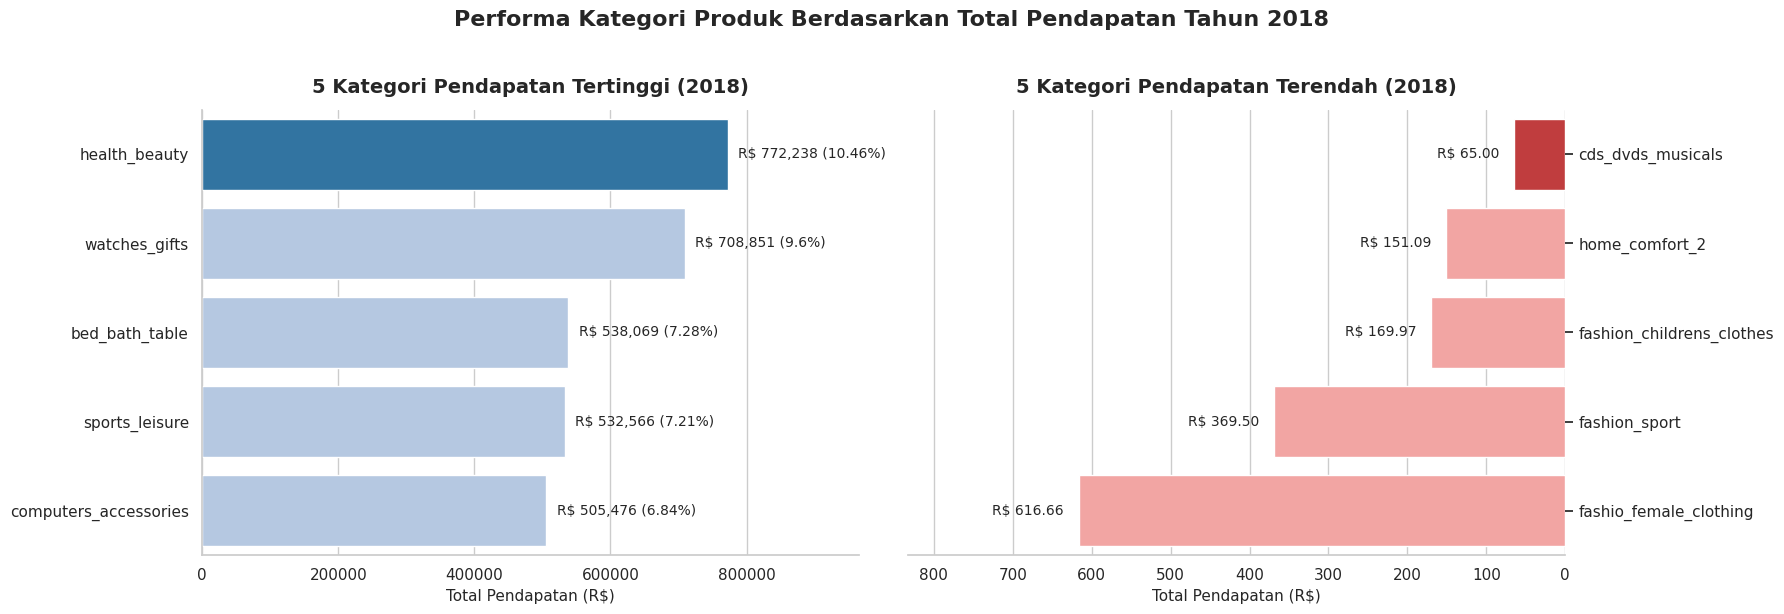

In [6]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

top_5_cat = revenue_by_category_2018.head(5)
bottom_5_cat = revenue_by_category_2018.tail(5).sort_values(by="total_revenue", ascending=True)

colors_top = ["#1f77b4", "#aec7e8", "#aec7e8", "#aec7e8", "#aec7e8"]
colors_bottom = ["#d62728", "#ff9896", "#ff9896", "#ff9896", "#ff9896"]

# Grafik Kiri: Top 5 Kategori Pendapatan Tertinggi
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=top_5_cat,
    palette=colors_top,
    hue="product_category_name_english",
    legend=False,
    ax=ax[0]
)
ax[0].set_title("5 Kategori Pendapatan Tertinggi (2018)", fontsize=14, fontweight="bold", pad=12)
ax[0].set_xlabel("Total Pendapatan (R$)", fontsize=11)
ax[0].set_ylabel(None)
ax[0].set_xlim(0, top_5_cat["total_revenue"].max() * 1.25)

for idx, row in enumerate(top_5_cat.itertuples()):
    ax[0].text(
        row.total_revenue + (top_5_cat["total_revenue"].max() * 0.02),
        idx,
        f"R$ {row.total_revenue:,.0f} ({row._5}%)",
        va="center",
        fontsize=10
    )

# Grafik Kanan: Bottom 5 Kategori Pendapatan Terendah
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=bottom_5_cat,
    palette=colors_bottom,
    hue="product_category_name_english",
    legend=False,
    ax=ax[1]
)
ax[1].set_title("5 Kategori Pendapatan Terendah (2018)", fontsize=14, fontweight="bold", pad=12)
ax[1].set_xlabel("Total Pendapatan (R$)", fontsize=11)
ax[1].set_ylabel(None)
ax[1].invert_xaxis()
ax[1].yaxis.set_label_position("right")
ax[1].yaxis.tick_right()
ax[1].set_xlim(bottom_5_cat["total_revenue"].max() * 1.35, 0)

for idx, row in enumerate(bottom_5_cat.itertuples()):
    ax[1].text(
        row.total_revenue + (bottom_5_cat["total_revenue"].max() * 0.03),
        idx,
        f"R$ {row.total_revenue:,.2f}",
        va="center",
        ha="right",
        fontsize=10
    )

sns.despine(ax=ax[0], top=True, right=True)
sns.despine(ax=ax[1], top=True, left=True)
plt.suptitle("Performa Kategori Produk Berdasarkan Total Pendapatan Tahun 2018", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Negara Bagian dengan Jumlah Pelanggan Terbanyak & Persebaran Pelanggan di Setiap Negara Bagian (Tahun 2018)

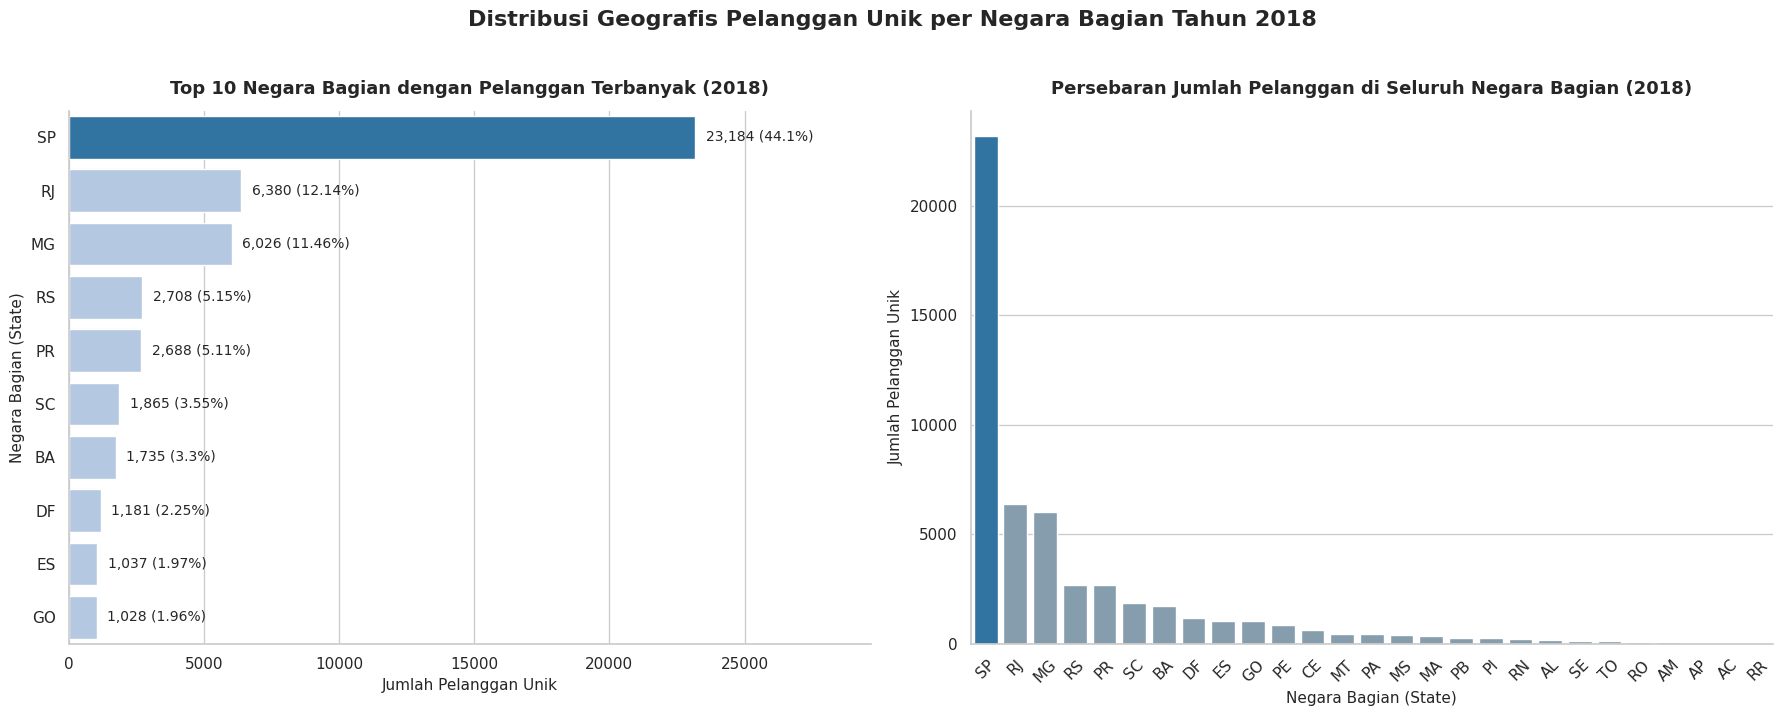

In [7]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

# Grafik Kiri: Top 10 Negara Bagian dengan Pelanggan Terbanyak (2018)
top_10_states = customer_by_state_2018.head(10)
colors_state = ["#1f77b4" if st == "SP" else "#aec7e8" for st in top_10_states["customer_state"]]

sns.barplot(
    x="unique_customers",
    y="customer_state",
    data=top_10_states,
    palette=colors_state,
    hue="customer_state",
    legend=False,
    ax=ax[0]
)
ax[0].set_title("Top 10 Negara Bagian dengan Pelanggan Terbanyak (2018)", fontsize=13, fontweight="bold", pad=12)
ax[0].set_xlabel("Jumlah Pelanggan Unik", fontsize=11)
ax[0].set_ylabel("Negara Bagian (State)", fontsize=11)
ax[0].set_xlim(0, top_10_states["unique_customers"].max() * 1.28)

for idx, row in enumerate(top_10_states.itertuples()):
    ax[0].text(
        row.unique_customers + 400,
        idx,
        f"{row.unique_customers:,} ({row._5}%)",
        va="center",
        fontsize=10
    )

# Grafik Kanan: Persebaran Jumlah Pelanggan di Seluruh Negara Bagian (2018)
all_states_colors = ["#1f77b4" if st == "SP" else "#7f9eb2" for st in customer_by_state_2018["customer_state"]]
sns.barplot(
    x="customer_state",
    y="unique_customers",
    data=customer_by_state_2018,
    palette=all_states_colors,
    hue="customer_state",
    legend=False,
    ax=ax[1]
)
ax[1].set_title("Persebaran Jumlah Pelanggan di Seluruh Negara Bagian (2018)", fontsize=13, fontweight="bold", pad=12)
ax[1].set_xlabel("Negara Bagian (State)", fontsize=11)
ax[1].set_ylabel("Jumlah Pelanggan Unik", fontsize=11)
ax[1].tick_params(axis="x", rotation=45)

sns.despine(ax=ax[0], top=True, right=True)
sns.despine(ax=ax[1], top=True, right=True)
plt.suptitle("Distribusi Geografis Pelanggan Unik per Negara Bagian Tahun 2018", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
* **Insight Pertanyaan 1 (Performa Pendapatan Kategori Produk Tahun 2018):**
  * Kategori **`health_beauty`** menjadi penyumbang pendapatan (*revenue*) tertinggi sepanjang tahun 2018 dengan nilai **R$ 772.238 (10,46%)**, diikuti oleh **`watches_gifts`** sebesar **R$ 708.851 (9,60%)**, **`bed_bath_table`** sebesar **R$ 538.069 (7,28%)**, **`sports_leisure`** sebesar **R$ 532.566 (7,21%)**, dan **`computers_accessories`** sebesar **R$ 505.476 (6,84%)**. Kelima kategori teratas ini secara kolektif menyumbang **41,39%** dari total pendapatan tahun 2018.

  * Sebaliknya, kategori dengan pendapatan terendah ditempati oleh **`cds_dvds_musicals`** dengan total hanya **R$ 65,00**, diikuti oleh **`home_comfort_2`** (**R$ 151,09**), **`fashion_childrens_clothes`** (**R$ 169,97**), **`fashion_sport`** (**R$ 369,50**), dan **`fashio_female_clothing`** (**R$ 616,66**), yang menunjukkan permintaan pasar sangat minim pada kelima kategori tersebut.

* **Insight Pertanyaan 2 (Persebaran Geografis Pelanggan Tahun 2018):**
  * Negara bagian **SP (São Paulo)** memiliki jumlah pelanggan unik terbanyak sepanjang tahun 2018 yaitu **23.184 pelanggan (44,10%)**, jauh melampaui posisi kedua **RJ (Rio de Janeiro)** sebanyak **6.380 pelanggan (12,14%)** dan posisi ketiga **MG (Minas Gerais)** sebanyak **6.026 pelanggan (11,46%)**.
  
  * Grafik persebaran seluruh 27 negara bagian memperlihatkan ketimpangan geografis yang sangat tajam: lebih dari dua pertiga basis pelanggan (**67,70%**) terkonsentrasi di tiga negara bagian wilayah tenggara (**SP, RJ, dan MG**), sedangkan negara bagian di wilayah utara seperti **AC (Acre)** dan **RR (Roraima)** memiliki jumlah pelanggan paling sedikit (di bawah 30 pelanggan unik selama tahun 2018).

## Analisis Lanjutan (Opsional)

### RFM Analysis & Customer Segmentation (Tahun 2018)
Untuk memahami perilaku pembelian pelanggan selama tahun 2018 tanpa menggunakan algoritma *machine learning*, dilakukan **RFM Analysis** berbasis `customer_unique_id` menggunakan tiga indikator utama:
- **Recency (R):** Jumlah hari sejak transaksi terakhir pelanggan hingga akhir periode pengamatan tahun 2018.
- **Frequency (F):** Total transaksi pesanan unik yang dilakukan pelanggan selama tahun 2018.
- **Monetary (M):** Total nilai pengeluaran (*revenue*) pelanggan selama tahun 2018.

Berdasarkan kombinasi skor kuantil R, F, dan M, pelanggan dikelompokkan ke dalam 5 segmen: **Champions**, **Loyal Customers**, **Potential Loyalists**, **Recent Customers**, dan **At Risk / Hibernating**.

--- RINGKASAN SEGMENTASI PELANGGAN RFM (2018) ---
                 segment  customer_count  avg_recency  avg_frequency  \
0  At Risk / Hibernating           25774       187.59           1.00   
1       Recent Customers           12922        66.74           1.00   
2    Potential Loyalists           12745        69.66           1.00   
3        Loyal Customers             615       163.53           2.05   
4              Champions             509        66.80           2.11   

   avg_monetary  share (%)  
0        135.15      49.03  
1         47.20      24.58  
2        235.35      24.25  
3        214.12       1.17  
4        317.41       0.97  


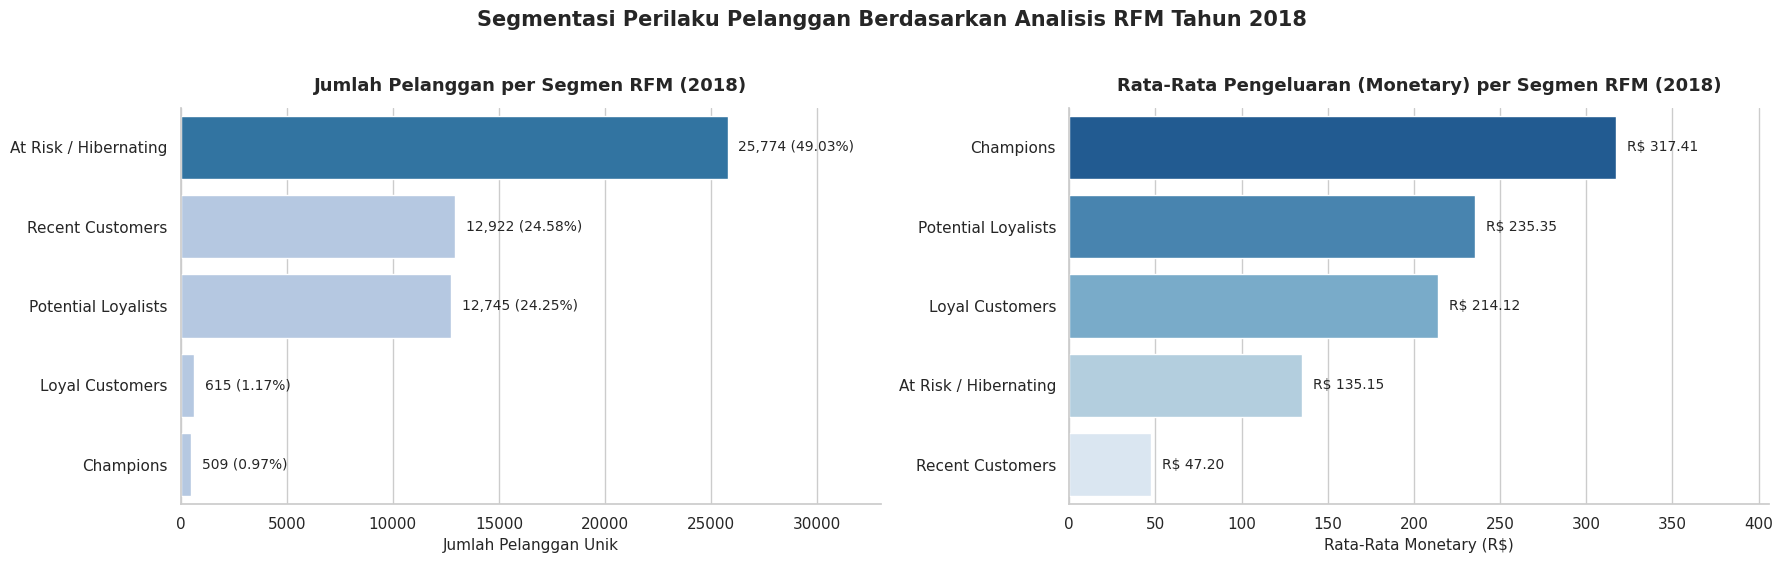


File 'dashboard/main_data.csv' berhasil disimpan!


In [8]:
# 1. Menentukan tanggal acuan (1 hari setelah transaksi terakhir di tahun 2018)
recent_date_2018 = df_2018["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# 2. Menghitung nilai Recency, Frequency, dan Monetary per pelanggan unik (2018)
rfm_df = df_2018.groupby("customer_unique_id", as_index=False).agg(
    recency=("order_purchase_timestamp", lambda x: (recent_date_2018 - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
)

# 3. Memberikan skor RFM (1 = Terendah, 4 = Terbaik)
rfm_df["r_score"] = pd.qcut(rfm_df["recency"].rank(method="first"), q=4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["f_score"] = rfm_df["frequency"].apply(lambda x: 4 if x >= 3 else (3 if x == 2 else 1))
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"].rank(method="first"), q=4, labels=[1, 2, 3, 4]).astype(int)

# 4. Mengelompokkan pelanggan ke dalam segmen berdasarkan skor RFM
def categorize_rfm(row):
    if row["r_score"] >= 3 and row["f_score"] >= 3 and row["m_score"] >= 3:
        return "Champions"
    elif row["f_score"] >= 3:
        return "Loyal Customers"
    elif row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Potential Loyalists"
    elif row["r_score"] >= 3:
        return "Recent Customers"
    else:
        return "At Risk / Hibernating"

rfm_df["segment"] = rfm_df.apply(categorize_rfm, axis=1)

# 5. Membuat ringkasan metrik tiap segmen RFM
rfm_summary = (
    rfm_df.groupby("segment", as_index=False)
    .agg(
        customer_count=("customer_unique_id", "count"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean")
    )
    .sort_values(by="customer_count", ascending=False)
    .reset_index(drop=True)
)
rfm_summary["share (%)"] = (rfm_summary["customer_count"] / rfm_summary["customer_count"].sum() * 100).round(2)

print("--- RINGKASAN SEGMENTASI PELANGGAN RFM (2018) ---")
print(rfm_summary.round(2))

# 6. Visualisasi Distribusi Pelanggan & Rata-Rata Monetary per Segmen RFM
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 5.5))

seg_colors = ["#1f77b4" if i == 0 else "#aec7e8" for i in range(len(rfm_summary))]
sns.barplot(
    x="customer_count",
    y="segment",
    data=rfm_summary,
    palette=seg_colors,
    hue="segment",
    legend=False,
    ax=ax[0]
)
ax[0].set_title("Jumlah Pelanggan per Segmen RFM (2018)", fontsize=13, fontweight="bold", pad=12)
ax[0].set_xlabel("Jumlah Pelanggan Unik", fontsize=11)
ax[0].set_ylabel(None)
ax[0].set_xlim(0, rfm_summary["customer_count"].max() * 1.28)

for idx, row in enumerate(rfm_summary.itertuples()):
    ax[0].text(
        row.customer_count + (rfm_summary["customer_count"].max() * 0.02),
        idx,
        f"{row.customer_count:,} ({row._6}%)",
        va="center",
        fontsize=10
    )

rfm_mon_sorted = rfm_summary.sort_values(by="avg_monetary", ascending=False)
sns.barplot(
    x="avg_monetary",
    y="segment",
    data=rfm_mon_sorted,
    palette="Blues_r",
    hue="segment",
    legend=False,
    ax=ax[1]
)
ax[1].set_title("Rata-Rata Pengeluaran (Monetary) per Segmen RFM (2018)", fontsize=13, fontweight="bold", pad=12)
ax[1].set_xlabel("Rata-Rata Monetary (R$)", fontsize=11)
ax[1].set_ylabel(None)
ax[1].set_xlim(0, rfm_mon_sorted["avg_monetary"].max() * 1.28)

for idx, row in enumerate(rfm_mon_sorted.itertuples()):
    ax[1].text(
        row.avg_monetary + (rfm_mon_sorted["avg_monetary"].max() * 0.02),
        idx,
        f"R$ {row.avg_monetary:,.2f}",
        va="center",
        fontsize=10
    )

sns.despine(ax=ax[0], top=True, right=True)
sns.despine(ax=ax[1], top=True, right=True)
plt.suptitle("Segmentasi Perilaku Pelanggan Berdasarkan Analisis RFM Tahun 2018", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 7. Menyimpan dataset bersih ke folder dashboard/main_data.csv untuk Streamlit
os.makedirs("dashboard", exist_ok=True)
all_df.to_csv(os.path.join("dashboard", "main_data.csv"), index=False)
print("\nFile 'dashboard/main_data.csv' berhasil disimpan!")

**Insight:** (Opsional)
* **Dominasi Pembeli Transaksi Tunggal (*One-Time Buyers*):** Sebagian besar pelanggan pada tahun 2018 hanya melakukan satu kali transaksi (`frequency = 1`), sehingga populasi pelanggan didominasi oleh segmen **At Risk / Hibernating** (pelanggan lama yang belum bertransaksi kembali) serta **Recent Customers** dan **Potential Loyalists** (pelanggan baru yang baru bertransaksi dalam beberapa bulan terakhir).

* **Nilai Belanja Tinggi pada Pelanggan Berulang:** Segmen **Champions** dan **Loyal Customers** memiliki porsi jumlah pelanggan yang jauh lebih kecil dibandingkan segmen lainnya, namun mencatat frekuensi pembelian berulang (*repeat order*) tertinggi serta rata-rata pengeluaran (**Monetary**) yang jauh lebih besar per pelanggan, menjadikannya kelompok paling bernilai bagi keberlanjutan pendapatan bisnis.

## Conclusion & Recommendation

* **Conclusion Pertanyaan 1:** Sepanjang tahun 2018, kategori produk yang menghasilkan total pendapatan (*revenue*) tertinggi adalah **`health_beauty`** sebesar **BRL 772.238 (10,46%)**, diikuti oleh **`watches_gifts`** (**BRL 708.851 / 9,60%**), **`bed_bath_table`** (**BRL 538.069 / 7,28%**), **`sports_leisure`** (**BRL 532.566 / 7,21%**), dan **`computers_accessories`** (**BRL 505.476 / 6,84%**). Sebaliknya, lima kategori dengan total pendapatan terendah adalah **`cds_dvds_musicals`** (**BRL 65,00**), **`home_comfort_2`** (**BRL 151,09**), **`fashion_childrens_clothes`** (**BRL 169,97**), **`fashion_sport`** (**BRL 369,50**), dan **`fashio_female_clothing`** (**BRL 616,66**).

* **Conclusion Pertanyaan 2:** Berdasarkan data transaksi selama tahun 2018, negara bagian (*state*) dengan jumlah pelanggan terbanyak adalah **SP (São Paulo)** sebanyak **23.184 pelanggan unik (44,10%)**, diikuti oleh **RJ (Rio de Janeiro)** dengan **6.380 pelanggan (12,14%)** dan **MG (Minas Gerais)** dengan **6.026 pelanggan (11,46%)**. Persebaran pelanggan di seluruh **27 negara bagian** menunjukkan konsentrasi sangat tinggi di wilayah tenggara Brasil (tiga negara bagian teratas mencakup **67,70%** dari total pelanggan), sedangkan negara bagian di wilayah utara seperti **RR (Roraima)** dan **AC (Acre)** memiliki kontribusi terendah (masing-masing hanya **0,05%**).

**Rekomendasi Action Item:**
* **Prioritas Kampanye & Manajemen Inventaris Produk:** Mengalokasikan anggaran promosi utama, penempatan halaman depan (*featured placement*), dan menjaga ketersediaan stok pada 5 kategori penyumbang pendapatan tertinggi (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, dan `computers_accessories`), serta melakukan evaluasi efisiensi katalog pada kategori berpendapatan sangat rendah seperti `cds_dvds_musicals` dan `home_comfort_2`.

* **Optimalisasi Rantai Pasok & Ekspansi Pasar Regional:** Memperkuat kapasitas pusat distribusi (*fulfillment center*) di wilayah **SP, RJ, dan MG** untuk menjaga kecepatan pengiriman di pasar utama, sekaligus meluncurkan program subsidi ongkos kirim (*free shipping voucher*) khusus bagi pelanggan di luar wilayah tenggara guna meningkatkan penetrasi pasar di negara bagian dengan pangsa rendah.

* **Strategi Retensi Pelanggan Berbasis Segmen RFM:** Mengirimkan kupon diskon pembelian kedua (*second-purchase incentive*) secara otomatis kepada segmen **Recent Customers** dan **Potential Loyalists** dalam 30 hari setelah transaksi pertama untuk meningkatkan tingkat *repeat order*, serta memberikan program loyalitas eksklusif bagi segmen **Champions** dan **Loyal Customers**.